# Projeto I, Etapa 3 (Grupo 6)
## Data Storytelling: análises de apoio à narrativa

Este notebook complementa a análise exploratória da Etapa 2 (`analise_exploratoria_unip_tic.ipynb`). Ele não repete aquela análise. Aqui estão as tabelas e os gráficos que sustentam a história contada no esboço da Etapa 3 e no vídeo da Etapa 4.

A história tem quatro momentos: **setup** (a UNIP e a pergunta), **conflito** (ofertas e vagas contra alunos), **ponto de virada** (onde estão os alunos) e **resolução** (recomendações).

Base: Microdados do Censo da Educação Superior 2024 (Inep), recorte UNIP (CO_IES = 322) e área CINE Computação e TIC. Cada linha é a oferta de um curso em um município.

Bibliotecas usadas: pandas e numpy para os cálculos, seaborn e matplotlib para os gráficos.

## 1. Leitura e preparação da base

O CSV está na pasta `data/`, por isso o caminho começa com `../`. A coluna `MODALIDADE` é criada só para deixar as tabelas e os gráficos legíveis (1 = Presencial, 2 = EAD).

A base de análise por localidade (`base`) usa só as linhas com `TP_DIMENSAO` 1 (sede presencial) e 2 (polo EAD). As 10 linhas com dimensão 3 e 4 são totais nacionais do EAD, sem município, e ficam separadas em `agregados`.

Neste notebook, cada registro é chamado de **oferta**: um curso oferecido em um município. Uma oferta não é um polo físico. Um mesmo polo pode aparecer em várias ofertas (uma por curso), e os dados só cobrem os cursos de TIC.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# cores fixas para as duas modalidades, usadas em todos os gráficos
cores = {"Presencial": "#F28E2B", "EAD": "#1F4E79"}

df = pd.read_csv("../data/unip_tic_variaveis_selecionadas.csv", sep=";", encoding="utf-8")
df["MODALIDADE"] = df["TP_MODALIDADE_ENSINO"].map({1: "Presencial", 2: "EAD"})

base = df[df["TP_DIMENSAO"].isin([1, 2])].copy()
agregados = df[df["TP_DIMENSAO"].isin([3, 4])].copy()

print("Linhas e colunas da base completa:", df.shape[0], "e", df.shape[1] - 1)
print("Linhas da base por localidade:", len(base))
print("Linhas agregadas (totais nacionais do EAD):", len(agregados))

Linhas e colunas da base completa: 1651 e 18
Linhas da base por localidade: 1641
Linhas agregadas (totais nacionais do EAD): 10


## 2. Estatística descritiva com variância

Na Etapa 2 a tabela de estatística descritiva não mostrava a variância. Aqui ela entra, junto com o desvio padrão e o coeficiente de variação (CV, em %). O CV acima de 400% mostra dispersão muito alta, ou seja, poucos registros têm valores altos e a maioria tem valores baixos ou zero.

In [2]:
num_cols = ["QT_VG_TOTAL", "QT_INSCRITO_TOTAL", "QT_ING", "QT_MAT", "QT_CONC"]

desc = base[num_cols].agg(["count", "mean", "var", "std", "min", "median", "max"]).T
desc["CV (%)"] = desc["std"] / desc["mean"] * 100
desc = desc.rename(columns={"count": "n", "mean": "média", "var": "variância",
                            "std": "desvio", "min": "mín", "median": "mediana", "max": "máx"})
desc.round(2)

,n,média,variância,desvio,mín,mediana,máx,CV (%)
QT_VG_TOTAL,1641.0,9.12,2257.83,47.52,0.0,0.0,504.0,520.80
QT_INSCRITO_TOTAL,1641.0,12.70,5700.07,75.50,0.0,0.0,1207.0,594.56
QT_ING,1641.0,10.76,2266.04,47.60,0.0,1.0,1187.0,442.59
QT_MAT,1641.0,13.78,3531.60,59.43,0.0,1.0,1154.0,431.35
QT_CONC,1641.0,2.42,136.97,11.70,0.0,0.0,238.0,482.78


## 3. Perfil de cada uma das 18 colunas

A tabela resume, para cada variável selecionada, o tipo, quantos valores existem, quantos estão ausentes e quantos são distintos. Para as numéricas aparecem também o mínimo e o máximo. Para as categóricas aparece o valor mais frequente (moda).

Os valores ausentes de `NO_REGIAO`, `SG_UF` e `NO_MUNICIPIO` são justamente as 10 linhas agregadas do EAD, que não têm localização.

In [3]:
perfil = []
for col in df.columns.drop("MODALIDADE"):
    serie = df[col]
    linha = {"variável": col,
             "tipo": "numérica" if col.startswith("QT_") else "categórica/código",
             "n": int(serie.notna().sum()),
             "ausentes": int(serie.isna().sum()),
             "distintos": int(serie.nunique())}
    if col.startswith("QT_"):
        linha["mín"] = int(serie.min())
        linha["máx"] = int(serie.max())
        linha["moda"] = ""
    else:
        linha["mín"] = ""
        linha["máx"] = ""
        linha["moda"] = str(serie.mode().iloc[0])
    perfil.append(linha)

perfil = pd.DataFrame(perfil)
perfil

,variável,tipo,n,ausentes,distintos,mín,máx,moda
0,NU_ANO_CENSO,categórica/código,1651,0,1,,,2024
1,CO_IES,categórica/código,1651,0,1,,,322
2,CO_CURSO,categórica/código,1651,0,81,,,1286800
3,NO_CURSO,categórica/código,1651,0,7,,,Análise E Desenvolvimento De Sistemas
4,CO_CINE_AREA_GERAL,categórica/código,1651,0,1,,,6
5,NO_CINE_AREA_GERAL,categórica/código,1651,0,1,,,Computação e Tecnologias da Informação e Comun...
6,NO_CINE_ROTULO,categórica/código,1651,0,6,,,Sistemas de informação
7,TP_GRAU_ACADEMICO,categórica/código,1651,0,2,,,3
8,TP_MODALIDADE_ENSINO,categórica/código,1651,0,2,,,2
9,TP_DIMENSAO,categórica/código,1651,0,4,,,2


## 4. Outliers pelo método IQR

O método do intervalo interquartil (IQR) é aplicado só a ingressantes, matrículas e concluintes. Para vagas e inscritos, Q1, Q3 e o limite superior são zero, então o método não se aplica. Os outliers não são erros. Eles são as maiores ofertas presenciais e EAD, e por isso foram mantidos.

In [4]:
linhas = []
for col in ["QT_ING", "QT_MAT", "QT_CONC"]:
    q1 = base[col].quantile(0.25)
    q3 = base[col].quantile(0.75)
    limite = q3 + 1.5 * (q3 - q1)
    qtd = int((base[col] > limite).sum())
    linhas.append({"variável": col, "Q1": q1, "Q3": q3, "limite superior": limite,
                   "outliers (qtd)": qtd, "outliers (%)": round(qtd / len(base) * 100, 1)})
pd.DataFrame(linhas)

,variável,Q1,Q3,limite superior,outliers (qtd),outliers (%)
0,QT_ING,0.0,3.0,7.5,234,14.3
1,QT_MAT,0.0,4.0,10.0,200,12.2
2,QT_CONC,0.0,1.0,2.5,174,10.6


## 5. Distribuição de ingressantes, matrículas e concluintes

Na Etapa 2 o histograma mostrava só as matrículas. Aqui as três variáveis de fluxo de alunos aparecem lado a lado, com escala logarítmica no eixo vertical. Sem essa escala, a barra das ofertas com poucos alunos esconderia todo o resto.

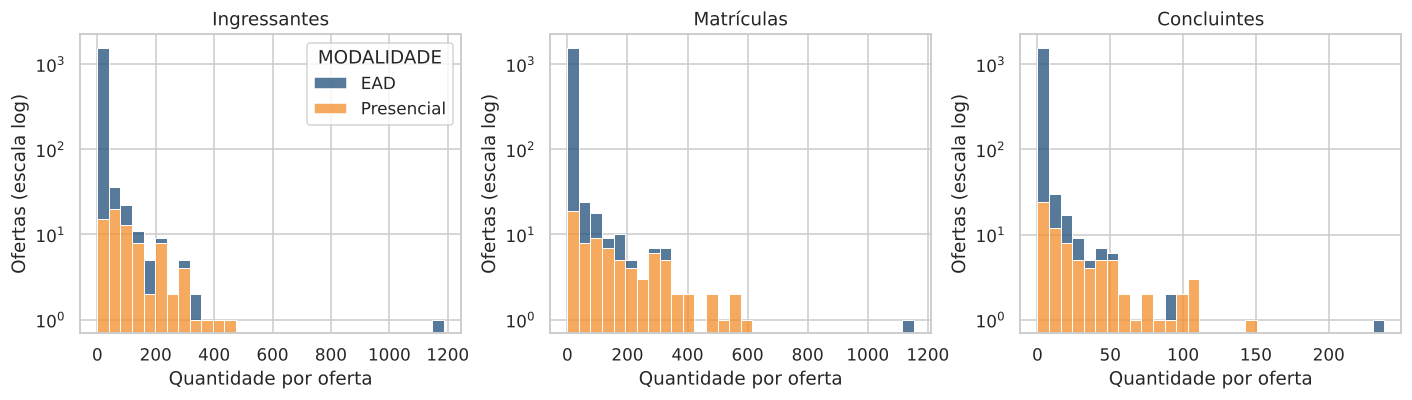

In [5]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.8))
titulos = {"QT_ING": "Ingressantes", "QT_MAT": "Matrículas", "QT_CONC": "Concluintes"}

for eixo, col in zip(eixos, titulos):
    sns.histplot(data=base, x=col, hue="MODALIDADE", palette=cores, hue_order=["EAD", "Presencial"],
                 bins=30, multiple="stack", ax=eixo)
    eixo.set_yscale("log")
    eixo.set_title(titulos[col])
    eixo.set_xlabel("Quantidade por oferta")
    eixo.set_ylabel("Ofertas (escala log)")
    if col != "QT_ING":
        eixo.get_legend().remove()

plt.tight_layout()
plt.savefig("fig_distribuicao_fluxo.png", bbox_inches="tight")
plt.show()

## 6. Conflito: ofertas contra matrículas

O comparativo mostra a base do conflito da história. O EAD tem quase todas as ofertas, mas o presencial tem a maior parte das matrículas.

            % das ofertas  % das matrículas
MODALIDADE                                 
EAD                  95.4              42.0
Presencial            4.6              58.0

Matrículas totais: 22608
MODALIDADE
EAD            9487
Presencial    13121
Name: QT_MAT, dtype: int64

Vagas e inscritos declarados nos totais nacionais do EAD:
QT_VG_TOTAL          341040
QT_INSCRITO_TOTAL     16937
dtype: int64


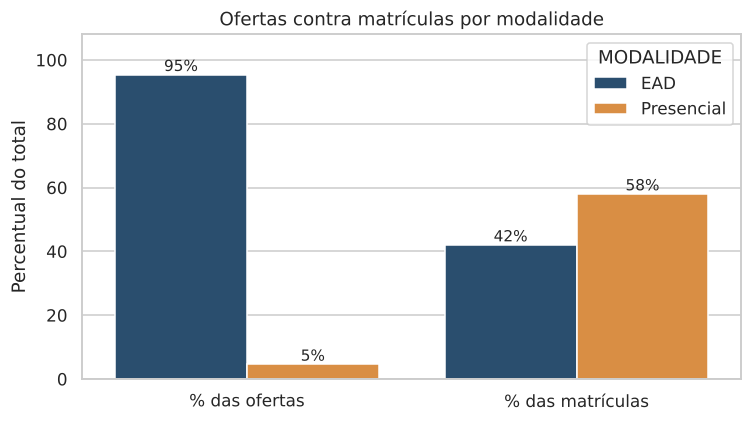

In [6]:
ofertas = base["MODALIDADE"].value_counts(normalize=True) * 100
matriculas = base.groupby("MODALIDADE")["QT_MAT"].sum()
matriculas_pct = matriculas / matriculas.sum() * 100

comp = pd.DataFrame({"% das ofertas": ofertas, "% das matrículas": matriculas_pct}).round(1)
print(comp)
print()
print("Matrículas totais:", int(matriculas.sum()))
print(matriculas)
print()
print("Vagas e inscritos declarados nos totais nacionais do EAD:")
print(agregados[["QT_VG_TOTAL", "QT_INSCRITO_TOTAL"]].sum())

comp_long = comp.reset_index(names="MODALIDADE").melt(id_vars="MODALIDADE", var_name="indicador", value_name="percentual")

plt.figure(figsize=(7, 4))
ax = sns.barplot(data=comp_long, x="indicador", y="percentual", hue="MODALIDADE", palette=cores,
                 hue_order=["EAD", "Presencial"])
for barra in ax.patches:
    if barra.get_height() > 0:
        ax.annotate(f"{barra.get_height():.0f}%", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                    ha="center", va="bottom", fontsize=10)
ax.set_xlabel("")
ax.set_ylabel("Percentual do total")
ax.set_title("Ofertas contra matrículas por modalidade")
ax.set_ylim(0, 108)
plt.tight_layout()
plt.savefig("fig_ofertas_vs_matriculas.png", bbox_inches="tight")
plt.show()

## 7. Ponto de virada: concentração das matrículas do EAD

As ofertas EAD são ordenadas da que tem mais matrículas para a que tem menos. A curva mostra quanto das matrículas fica nas primeiras ofertas. A tabela de porte agrupa as ofertas em faixas de matrículas.

Ofertas EAD (curso em um município): 1565
Ofertas que reúnem metade das matrículas: 31
Ofertas sem nenhuma matrícula: 427 ( 27.3 % )
Top 1% das ofertas: 40.1 % das matrículas
Top 5% das ofertas: 64.8 % das matrículas
Top 10% das ofertas: 74.8 % das matrículas


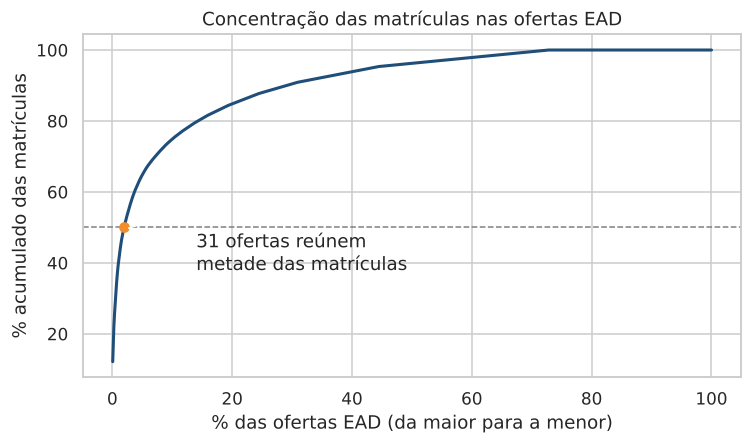

In [7]:
ead = base[base["TP_DIMENSAO"] == 2].copy()
ordenado = ead["QT_MAT"].sort_values(ascending=False).reset_index(drop=True)
acumulado = ordenado.cumsum() / ordenado.sum() * 100
metade = int((acumulado < 50).sum() + 1)

print("Ofertas EAD (curso em um município):", len(ead))
print("Ofertas que reúnem metade das matrículas:", metade)
print("Ofertas sem nenhuma matrícula:", int((ead["QT_MAT"] == 0).sum()),
      "(", round((ead["QT_MAT"] == 0).mean() * 100, 1), "% )")
print("Top 1% das ofertas:", round(acumulado.iloc[15], 1), "% das matrículas")
print("Top 5% das ofertas:", round(acumulado.iloc[77], 1), "% das matrículas")
print("Top 10% das ofertas:", round(acumulado.iloc[155], 1), "% das matrículas")

x = np.arange(1, len(ordenado) + 1) / len(ordenado) * 100
plt.figure(figsize=(7, 4.2))
plt.plot(x, acumulado, color=cores["EAD"], linewidth=2)
plt.axhline(50, color="gray", linestyle="--", linewidth=1)
plt.scatter([metade / len(ordenado) * 100], [50], color=cores["Presencial"], zorder=3)
plt.annotate(f"{metade} ofertas reúnem\nmetade das matrículas", (metade / len(ordenado) * 100, 50),
             xytext=(14, 38), arrowprops={"arrowstyle": "->"})
plt.xlabel("% das ofertas EAD (da maior para a menor)")
plt.ylabel("% acumulado das matrículas")
plt.title("Concentração das matrículas nas ofertas EAD")
plt.tight_layout()
plt.savefig("fig_concentracao_ead.png", bbox_inches="tight")
plt.show()

In [8]:
faixas = [-1, 0, 5, 20, 100, np.inf]
rotulos = ["0 (sem matrícula)", "1 a 5", "6 a 20", "21 a 100", "mais de 100"]

def tabela_porte(dados):
    dados = dados.copy()
    dados["faixa"] = pd.cut(dados["QT_MAT"], bins=faixas, labels=rotulos)
    t = dados.groupby("faixa", observed=False).agg(ofertas=("QT_MAT", "size"), matriculas=("QT_MAT", "sum"))
    t["% das ofertas"] = (t["ofertas"] / t["ofertas"].sum() * 100).round(1)
    t["% das matrículas"] = (t["matriculas"] / t["matriculas"].sum() * 100).round(1)
    return t

porte_ead = tabela_porte(ead)
porte_pres = tabela_porte(base[base["TP_DIMENSAO"] == 1])

print("Porte das ofertas EAD")
print(porte_ead)
print()
print("Porte das ofertas presenciais (sedes)")
print(porte_pres)

Porte das ofertas EAD
                   ofertas  matriculas  % das ofertas  % das matrículas
faixa                                                                  
0 (sem matrícula)      427           0           27.3               0.0
1 a 5                  892        1762           57.0              18.6
6 a 20                 173        1678           11.1              17.7
21 a 100                58        2328            3.7              24.5
mais de 100             15        3719            1.0              39.2

Porte das ofertas presenciais (sedes)
                   ofertas  matriculas  % das ofertas  % das matrículas
faixa                                                                  
0 (sem matrícula)        7           0            9.2               0.0
1 a 5                    4           7            5.3               0.1
6 a 20                   1          20            1.3               0.2
21 a 100                21        1323           27.6              10.1
mai

## 7.1 Escala por unidade

Compara o tamanho médio de uma oferta presencial (sede) com o de uma oferta EAD. A média é puxada pelas unidades grandes, por isso a mediana também aparece.

In [9]:
escala = base.groupby("MODALIDADE")["QT_MAT"].agg(ofertas="count", media="mean", mediana="median",
                                                  pct_sem_matricula=lambda s: (s == 0).mean() * 100).round(1)
escala

,ofertas,media,mediana,pct_sem_matricula
MODALIDADE,,,,
EAD,1565,6.1,1.0,27.3
Presencial,76,172.6,120.0,9.2


## 8. Ponto de virada: geografia das matrículas

A distribuição por região usa matrículas, e não a quantidade de registros, porque o que interessa à história é onde estão os alunos.

MODALIDADE     EAD  Presencial  Total  % do total
NO_REGIAO                                        
Sudeste       7067       12255  19322        85.5
Centro-Oeste  1111         737   1848         8.2
Norte          720         129    849         3.8
Nordeste       393           0    393         1.7
Sul            196           0    196         0.9

São Paulo: 18964 matrículas,  83.9 % do total


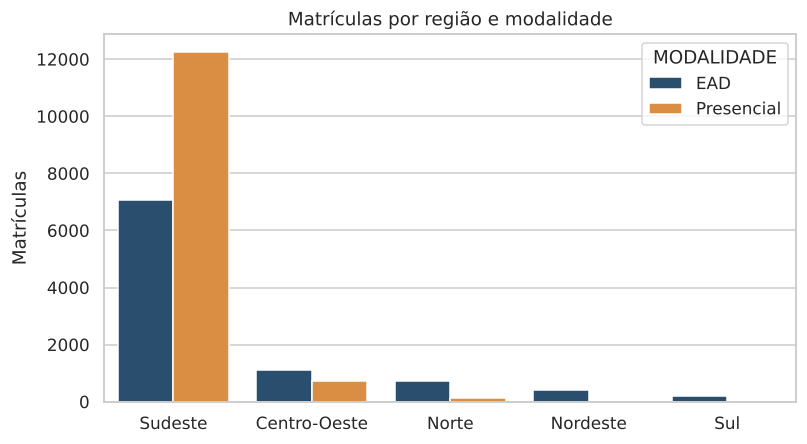


Municípios com oferta EAD: 490
Municípios com oferta EAD e nenhuma matrícula: 69
Estados com sede presencial: ['AM', 'DF', 'GO', 'SP']
Municípios com sede presencial: 18
Minas Gerais: 137 ofertas e 161 matrículas
Municípios com sede presencial: 18


In [10]:
reg = base.groupby(["NO_REGIAO", "MODALIDADE"])["QT_MAT"].sum().unstack(fill_value=0)
reg["Total"] = reg.sum(axis=1)
reg["% do total"] = (reg["Total"] / reg["Total"].sum() * 100).round(1)
reg = reg.sort_values("Total", ascending=False)
print(reg)

uf = base.groupby("SG_UF")["QT_MAT"].sum().sort_values(ascending=False)
print()
print("São Paulo:", int(uf["SP"]), "matrículas, ", round(uf["SP"] / uf.sum() * 100, 1), "% do total")

plot_reg = reg[["Presencial", "EAD"]].reset_index().melt(id_vars="NO_REGIAO", var_name="MODALIDADE", value_name="matrículas")

plt.figure(figsize=(7.5, 4.2))
ax = sns.barplot(data=plot_reg, x="NO_REGIAO", y="matrículas", hue="MODALIDADE", palette=cores,
                 hue_order=["EAD", "Presencial"])
ax.set_xlabel("")
ax.set_ylabel("Matrículas")
ax.set_title("Matrículas por região e modalidade")
plt.tight_layout()
plt.savefig("fig_matriculas_regiao.png", bbox_inches="tight")
plt.show()

# municípios com oferta EAD e nenhuma matrícula
mun = ead.groupby("NO_MUNICIPIO")["QT_MAT"].sum()
print()
print("Municípios com oferta EAD:", len(mun))
print("Municípios com oferta EAD e nenhuma matrícula:", int((mun == 0).sum()))

# onde existe sede presencial
pres = base[base["TP_DIMENSAO"] == 1]
print("Estados com sede presencial:", sorted(pres["SG_UF"].unique()))
print("Municípios com sede presencial:", pres["NO_MUNICIPIO"].nunique())

# um exemplo de baixa matrícula por oferta
mg = base[base["SG_UF"] == "MG"]
print("Minas Gerais:", len(mg), "ofertas e", int(mg["QT_MAT"].sum()), "matrículas")
print("Municípios com sede presencial:", pres["NO_MUNICIPIO"].nunique())

## 9. Indicadores por modalidade

Os indicadores abaixo são descritivos. **Matrículas por ingressante não é taxa de conversão**, porque as matrículas acumulam alunos de todos os períodos do curso. Servem para comparar as modalidades, e não para medir desempenho.

In [11]:
tot = base.groupby("MODALIDADE")[["QT_ING", "QT_MAT", "QT_CONC"]].sum()
ind = pd.DataFrame({
    "matrículas por ingressante": (tot["QT_MAT"] / tot["QT_ING"]).round(2),
    "concluintes por matrícula (%)": (tot["QT_CONC"] / tot["QT_MAT"] * 100).round(1),
    "concluintes por ingressante (%)": (tot["QT_CONC"] / tot["QT_ING"] * 100).round(1),
})
ind

,matrículas por ingressante,concluintes por matrícula (%),concluintes por ingressante (%)
MODALIDADE,,,
EAD,1.10,18.1,20.0
Presencial,1.45,17.2,24.9


## 9.1 Indicadores por grau acadêmico

O presencial tem mais alunos de bacharelado (cursos de 4 anos), e isso pesa nas razões gerais. Por isso os mesmos indicadores são calculados separando tecnólogo e bacharelado. No tecnólogo as duas modalidades ficam próximas. A diferença grande está no bacharelado do EAD, que é só Ciência da Computação.

In [12]:
grau = base.assign(GRAU=base["TP_GRAU_ACADEMICO"].map({1: "Bacharelado", 3: "Tecnólogo"}))
tot_grau = grau.groupby(["GRAU", "MODALIDADE"])[["QT_ING", "QT_MAT", "QT_CONC"]].sum()
tot_grau["matrículas por ingressante"] = (tot_grau["QT_MAT"] / tot_grau["QT_ING"]).round(2)
tot_grau["concluintes por matrícula (%)"] = (tot_grau["QT_CONC"] / tot_grau["QT_MAT"] * 100).round(1)
tot_grau["concluintes por ingressante (%)"] = (tot_grau["QT_CONC"] / tot_grau["QT_ING"] * 100).round(1)
tot_grau

QT_ING  QT_MAT  QT_CONC  matrículas por ingressante  \
GRAU        MODALIDADE                                                        
Bacharelado EAD           1246    1496       27                        1.20   
            Presencial    3130    6365      650                        2.03   
Tecnólogo   EAD           7350    7991     1694                        1.09   
            Presencial    5924    6756     1607                        1.14   

                        concluintes por matrícula (%)  \
GRAU        MODALIDADE                                  
Bacharelado EAD                                   1.8   
            Presencial                           10.2   
Tecnólogo   EAD                                  21.2   
            Presencial                           23.8   

                        concluintes por ingressante (%)  
GRAU        MODALIDADE                                   
Bacharelado EAD                                     2.2  
            Presencial                             20.8  
Tecnólogo   EAD                                    23.0  
            Presencial                             27.1

## 10. Cursos: matrículas e conclusão por modalidade

Análise e Desenvolvimento de Sistemas é o curso com mais matrículas nas duas modalidades. Ciência da Computação chama a atenção pela diferença na conclusão entre EAD e presencial.

In [13]:
curso = base.groupby(["NO_CURSO", "MODALIDADE"]).agg(ofertas=("QT_MAT", "size"),
                                                   matriculas=("QT_MAT", "sum"),
                                                   concluintes=("QT_CONC", "sum"))
curso["concluintes por matrícula (%)"] = (curso["concluintes"] / curso["matriculas"] * 100).round(1)
curso.sort_values("matriculas", ascending=False)

,,ofertas,matriculas,concluintes,concluintes por matrícula (%)
NO_CURSO,MODALIDADE,,,,
Análise E Desenvolvimento De Sistemas,Presencial,25,5997,1395,23.3
Ciência Da Computação,Presencial,24,5505,534,9.7
Análise E Desenvolvimento De Sistemas,EAD,397,5218,1114,21.3
Gestão Da Tecnologia Da Informação,EAD,355,1647,342,20.8
Ciência Da Computação,EAD,291,1496,27,1.8
Sistemas De Informação,Presencial,9,860,116,13.5
Gestão Da Tecnologia Da Informação,Presencial,12,731,205,28.0
Segurança Da Informação,EAD,253,632,134,21.2
Redes De Computadores,EAD,269,494,104,21.1


## 11. Resumo para a narrativa

- **Setup:** 1.651 registros, 7 cursos, 490 municípios. Fonte: Censo da Educação Superior 2024 (Inep).
- **Conflito:** o EAD tem 95% das ofertas e vagas declaradas muito maiores, mas o presencial tem 58% das matrículas.
- **Ponto de virada:** metade das matrículas do EAD está em 31 das 1.565 ofertas, 27% das ofertas não têm aluno e 85% das matrículas estão no Sudeste.
- **Resolução:** revisar as ofertas de TIC sem matrícula, acompanhar a conclusão no EAD, avaliar crescimento fora do Sudeste e registrar vagas e inscritos por polo.

Limitações: um único ano, oferta não é polo físico (só vemos TIC), vagas e inscritos do EAD só nos totais nacionais e matrículas acumuladas.